# 2

### Nota: 10

Pon a prueba tus habilidades analíticas con un nuevo proyecto. En este caso, trabajarás con un dataset sobre precios de casas. ¿Y qué tienes que hacer? Pues bien, el objetivo principal es seas capaz de realizar un análisis de componentes principales (PCA) utilizando la librería scikit-learn para reducir las dimensiones del dataset a 30 componentes. El proceso incluirá la preparación, limpieza de los datos, y luego la aplicación de PCA. Así que no esperes más y ¡manos a la obra!

In [82]:
import numpy as np
import pandas as pd
import sklearn as sk
import matplotlib.pyplot as plt
import seaborn as sns

work_dir = "../media/1_lab5/2/"
file_dir = "dataset.csv"
seed = 112211

df = pd.read_csv(work_dir + file_dir)

In [83]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

Como hay 80 columnas, para poder distinguir entre números y cadenas de texto, vamos a hacer la limpieza de valores nulos en dos dataframes distintos

In [84]:
df_nums = df.select_dtypes(include = np.number)
df_str = df.select_dtypes(include = "O")

/tmp/ipykernel_33477/1737958089.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_str = df.select_dtypes(include = "O")


Veamos las columnas que tienen valores nulos para cada tipo (número y str)

In [85]:
nan_cols_num = df_nums.isna().sum().loc[df_nums.isna().sum() != 0].index
nan_cols_str = df_str.isna().sum().loc[df_str.isna().sum() != 0].index

print(f"Columnas numéricas con valores nulos: {nan_cols_num}")
print(f"Columnas categóricas con valores nulos: {nan_cols_str}")

Columnas numéricas con valores nulos: Index(['LotFrontage', 'MasVnrArea', 'GarageYrBlt'], dtype='str')
Columnas categóricas con valores nulos: Index(['Alley', 'MasVnrType', 'BsmtQual', 'BsmtCond', 'BsmtExposure',
       'BsmtFinType1', 'BsmtFinType2', 'Electrical', 'FireplaceQu',
       'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PoolQC',
       'Fence', 'MiscFeature'],
      dtype='str')


Imputamos los valores según corresponda.

In [86]:
for col in nan_cols_num:
    df[col] = df[col].fillna(df[col].median())

for col in nan_cols_str:
    df[col] = df[col].fillna(df[col].mode().iloc[0])

In [87]:
df.isna().sum().sum()

np.int64(0)

Hemos imputado los valores nulos. Vamos aplicar un get_dummies a las variables categóricas (str)

In [88]:
df = pd.get_dummies(data = df, prefix = df.select_dtypes(include = "O").columns).astype(int)

/tmp/ipykernel_33477/3031462978.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df = pd.get_dummies(data = df, prefix = df.select_dtypes(include = "O").columns).astype(int)


In [89]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Columns: 289 entries, Id to SaleCondition_Partial
dtypes: int64(289)
memory usage: 3.2 MB


Hemos codificado de forma exitosa todas las variables categóricas

Normalizamos con el StandardScaler

In [90]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
scaled = sc.fit_transform(df)
df = pd.DataFrame(data = scaled, columns = df.columns)

In [91]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,0.000000e+00,1.000343,-1.730865,-0.865432,0.000000,0.865432,1.730865
MSSubClass,1460.0,-8.455945e-17,1.000343,-0.872563,-0.872563,-0.163109,0.309859,3.147673
LotFrontage,1460.0,2.798370e-16,1.000343,-2.219047,-0.447940,-0.039223,0.414907,11.041546
LotArea,1460.0,-5.840077e-17,1.000343,-0.923729,-0.296991,-0.104063,0.108708,20.518273
OverallQual,1460.0,1.387018e-16,1.000343,-3.688413,-0.795151,-0.071836,0.651479,2.821425
...,...,...,...,...,...,...,...,...
SaleCondition_AdjLand,1460.0,1.703356e-17,1.000343,-0.052414,-0.052414,-0.052414,-0.052414,19.078784
SaleCondition_Alloca,1460.0,1.581688e-17,1.000343,-0.091035,-0.091035,-0.091035,-0.091035,10.984838
SaleCondition_Family,1460.0,-3.406712e-17,1.000343,-0.117851,-0.117851,-0.117851,-0.117851,8.485281
SaleCondition_Normal,1460.0,-9.915965e-17,1.000343,-2.138345,0.467651,0.467651,0.467651,0.467651


Ahora aplicamos el PCA con 30 componentes

In [92]:
from sklearn.decomposition import PCA

pca = PCA(n_components = 30, random_state = seed)
df_pca = pd.DataFrame(pca.fit_transform(df), columns = [f"PCA_{n}" for n in range(1, pca.n_components_ + 1)])

In [93]:
df_pca.head()

,PCA_1,PCA_2,PCA_3,PCA_4,PCA_5,PCA_6,PCA_7,PCA_8,PCA_9,PCA_10,...,PCA_21,PCA_22,PCA_23,PCA_24,PCA_25,PCA_26,PCA_27,PCA_28,PCA_29,PCA_30
0,3.984425,-1.819464,-2.108880,2.017327,0.161607,1.645565,0.249183,-0.487582,-0.314067,-0.768906,...,1.058172,-0.457155,-1.097598,0.161439,-0.247184,-0.471327,0.368556,0.543057,1.473035,0.178408
1,0.116986,3.444672,-0.797626,0.421265,0.156915,0.296122,-0.729037,-0.996992,0.343365,-1.237168,...,1.797340,0.596152,0.280170,-1.995998,2.062976,0.725675,0.388180,0.019613,1.023016,-0.775109
2,4.785247,-0.804684,-1.410613,2.785941,0.623656,2.395230,0.073165,-0.820494,-0.477236,-1.079399,...,0.556086,0.159477,-1.121071,-0.813824,-0.006668,-0.471924,-0.854624,0.479969,0.809089,-0.201389
3,-1.937986,-0.972467,1.872634,1.435573,-0.944637,0.441331,-2.196049,0.239774,0.145152,0.988590,...,-2.146416,1.875933,1.467920,-0.928350,-0.341182,0.725008,0.695938,-1.346073,-0.585586,-0.042568
4,6.495751,-0.299339,0.586595,4.009403,0.296601,1.633900,0.485677,-0.201309,-1.228691,-1.564701,...,1.266660,0.598430,-0.803992,-0.546215,0.394102,-1.291568,-0.892522,-0.251486,0.241951,-0.270982


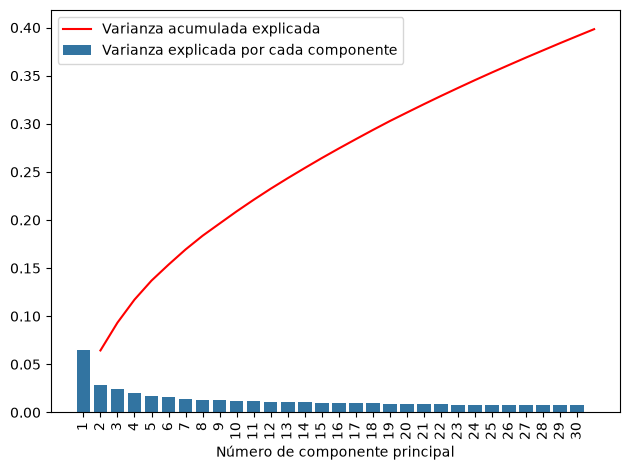

In [94]:
sns.barplot(x = range(1, pca.n_components_ + 1), y = pca.explained_variance_ratio_, label = "Varianza explicada por cada componente")
sns.lineplot(x = range(1, pca.n_components_ + 1), y = np.cumsum(pca.explained_variance_ratio_), color = "r", label = "Varianza acumulada explicada")
plt.xlabel("Número de componente principal")
plt.xticks(rotation = 90)
plt.tight_layout()

In [95]:
sum_variance = np.sum(pca.explained_variance_ratio_)
print(f"Varianza explicada acumulada por los 30 componentes: {round(sum_variance * 100, 2)}%")

Varianza explicada acumulada por los 30 componentes: 39.84%


Con los 30 componentes llegamos a explicar casi un 40% de los datos originales. Este es un valor significativamente más bajo que el 80% que está estipulado como valor para considerar que la reducción de dimensionalidad es efectiva. Habría que probar con un número mayor, tengamos en cuenta que se partía de 289 variables.